# 1st Assignment

Filo logico:

Per le due condizioni distinte:

* raccogliere per diametro (di tornitura) -> {potenza} C&NC
* [Ptot] -> [Pc] -> [Fc] -> [Kc] -> KC_avg

In [1]:
# Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
#import matplotlib.ticker as ticker
import numpy as np
import os
# Ensure images directory exists
os.makedirs('images', exist_ok=True)

In [2]:
# Tool parameters

ap = 1  #(mm)
f = 0.2 #(mm)
Vc = 150    #(m/min)
N = 1200    #(rpm)

## Loading data

In [3]:
# File data CSV -> C:= cutting; NC := NON-cutting
filedataC150 = 'ANNACHPTVC150.csv'
filedataNC150 = 'ANNACHPTVC150VIDE.csv'
filedataC1200 = 'ANNACHPT1200RPM.csv'
filedataNC1200 = 'ANNACHPT1200RPMVIDE.csv'

In [4]:
# Reading csv
dfC150 = pd.read_csv(filedataC150, skiprows=10)
dfNC150 = pd.read_csv(filedataNC150, skiprows=10)
dfC1200 = pd.read_csv(filedataC1200, skiprows=10)
dfNC1200 = pd.read_csv(filedataNC1200, skiprows=10)

In [5]:
# Naming columns
dfC150.columns = [
    'time', #(s)
    'power',    #(W)
    'prog_pos_z',   # Programmed position
    'prog_pos_x',
    'meas_pos_z',   # Actual value of position 
    'meas_pos_x',
    'spindle1'  #(rpm)  # Spindle speed. Only the first data does not have the spindle 2 data
]

cols = ['time', 'power', 'prog_pos_z', 'prog_pos_x',
        'meas_pos_z', 'meas_pos_x', 'spindle1', 'spindle2']
for df in [dfNC150, dfC1200, dfNC1200]:
    df.columns = cols

In [6]:
# Defining indecis of columns
cols_to_convert = dfC150.columns.difference(['time'])

# Conversion to numeric type
for df in [dfC150, dfNC150, dfC1200, dfNC1200]:
    for col in cols_to_convert:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Suppressing Nan columns
for df in [dfC150, dfNC150, dfC1200, dfNC1200]:
    df.dropna(inplace=True)

## Filtering data per programmed cutting X position

In [7]:
## ==== Energy calculation ====
#
## Calculating dt
#for df in [dfC150, dfNC150, dfC1200, dfNC1200]:
#    df['delta_t'] = df['time'].diff()
#    df.loc[df.index[0], 'delta_t'] = 0
#
## Instantaneous energy (W x s / 1000 = kJ)
#for df in [dfC150, dfNC150, dfC1200, dfNC1200]:
#    df['energy_kJ'] = df['power'] * df['delta_t'] / 1000

In [8]:
# Vector in order to do for-loops
dfs = {'C150': dfC150, 'NC150': dfNC150, 'C1200': dfC1200, 'NC1200': dfNC1200}

# Filter data
for key, df in dfs.items():
    dfs[key] = df[(df['prog_pos_x'] >= 24) &    # cutting diameter
                  (df['prog_pos_x'] <= 46) &    # cutting diameter
                  (df['prog_pos_z'] <= 0) &     # cutting feed
                  (df['prog_pos_z'] >= -40) &   # cutting feed
                  (df['prog_pos_x'] % 1 == 0)   # programmed diameter is integer
                  ]
    
filt_dfC150 = dfs['C150']
filt_dfNC150 = dfs['NC150']
filt_dfC1200 = dfs['C1200']
filt_dfNC1200 = dfs['NC1200']

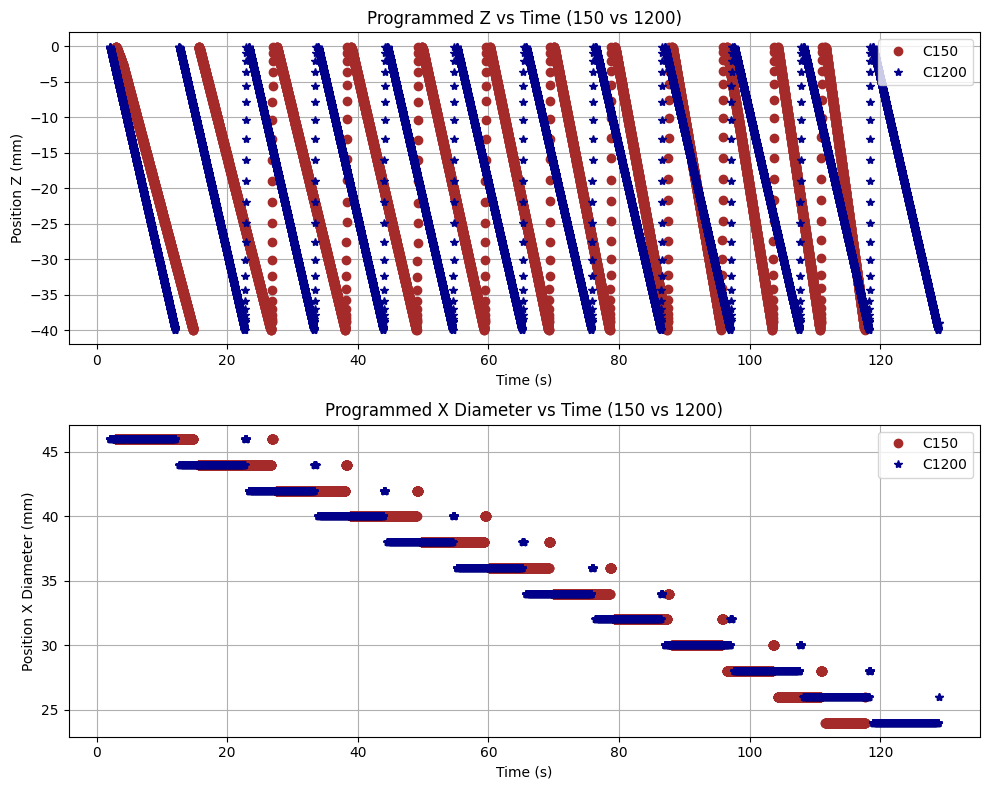

In [9]:
# Overall figure
fig = plt.figure(figsize=(10,8))
gs = gridspec.GridSpec(2,1)  # 2x2 grid

# Progammed position Z vs Time
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(filt_dfC150['time'], filt_dfC150['prog_pos_z'],
      label='C150', color='brown', marker='o', linestyle='none')
ax1.plot(filt_dfC1200['time'], filt_dfC1200['prog_pos_z'],
      label='C1200', color='darkblue', marker='*', linestyle='none')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Position Z (mm)')
ax1.set_title('Programmed Z vs Time (150 vs 1200)')

# Progammed position X Diameter vs Time
ax2 = fig.add_subplot(gs[1, 0])
ax2.plot(filt_dfC150['time'], filt_dfC150['prog_pos_x'],
      label='C150', color='brown', marker='o', linestyle='none')
ax2.plot(filt_dfC1200['time'], filt_dfC1200['prog_pos_x'],
      label='C1200', color='darkblue', marker='*', linestyle='none')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Position X Diameter (mm)')
ax2.set_title('Programmed X Diameter vs Time (150 vs 1200)')

for ax in [ax1, ax2]:
    ax.grid(True)
    ax.legend()

plt.tight_layout()
# Save figure as PNG in the notebook directory
plt.savefig('programmed_positions_150_1200.png', dpi=600, bbox_inches='tight')
plt.show()

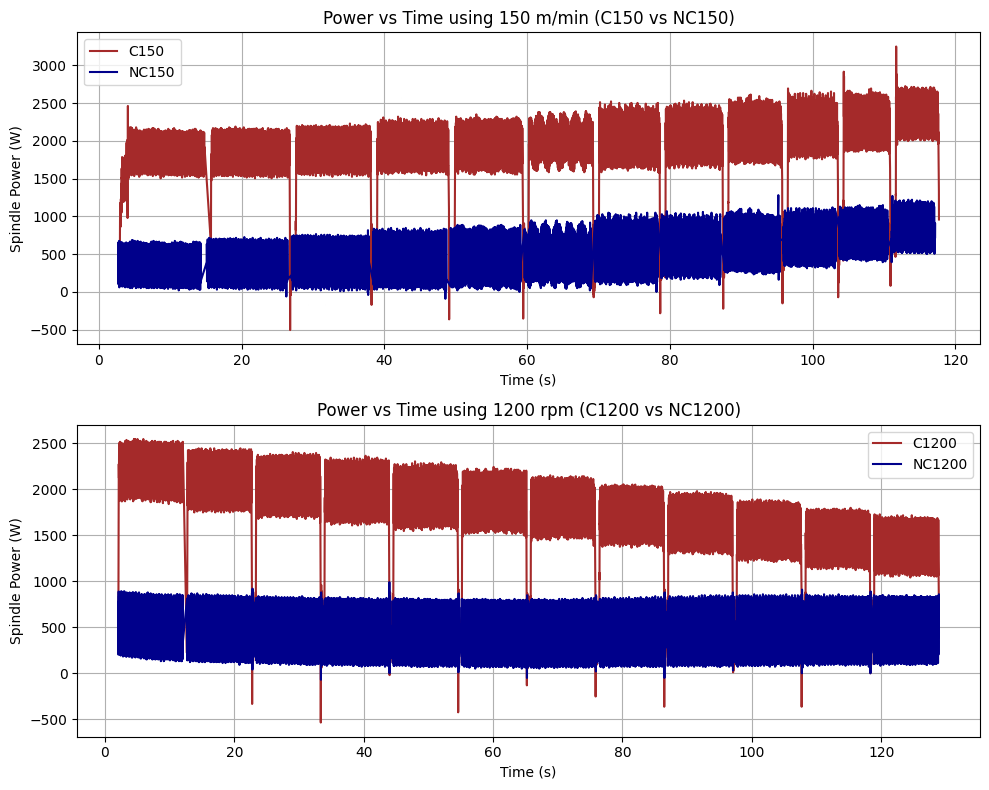

In [ ]:
# Overall figure
fig = plt.figure(figsize=(10,8))
gs = gridspec.GridSpec(2, 1)

# Power vs Time using constant cutting velocity
ax1 = fig.add_subplot(gs[0,0])
ax1.plot(filt_dfC150['time'], filt_dfC150['power'], label='C150', color='brown') 
ax1.plot(filt_dfNC150['time'], filt_dfNC150['power'], label='NC150', color='darkblue')
#ax1.set_xlim(25,28)
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Spindle Power (W)')
ax1.set_title('Power vs Time using 150 m/min (C150 vs NC150)')

# Power vs Time using constant spindle speed
ax2 = fig.add_subplot(gs[1,0])
ax2.plot(filt_dfC1200['time'], filt_dfC1200['power'], label='C1200', color='brown') 
ax2.plot(filt_dfNC1200['time'], filt_dfNC1200['power'], label='NC1200', color='darkblue')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Spindle Power (W)')
ax2.set_title('Power vs Time using 1200 rpm (C1200 vs NC1200)')

for ax in [ax1, ax2]:
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

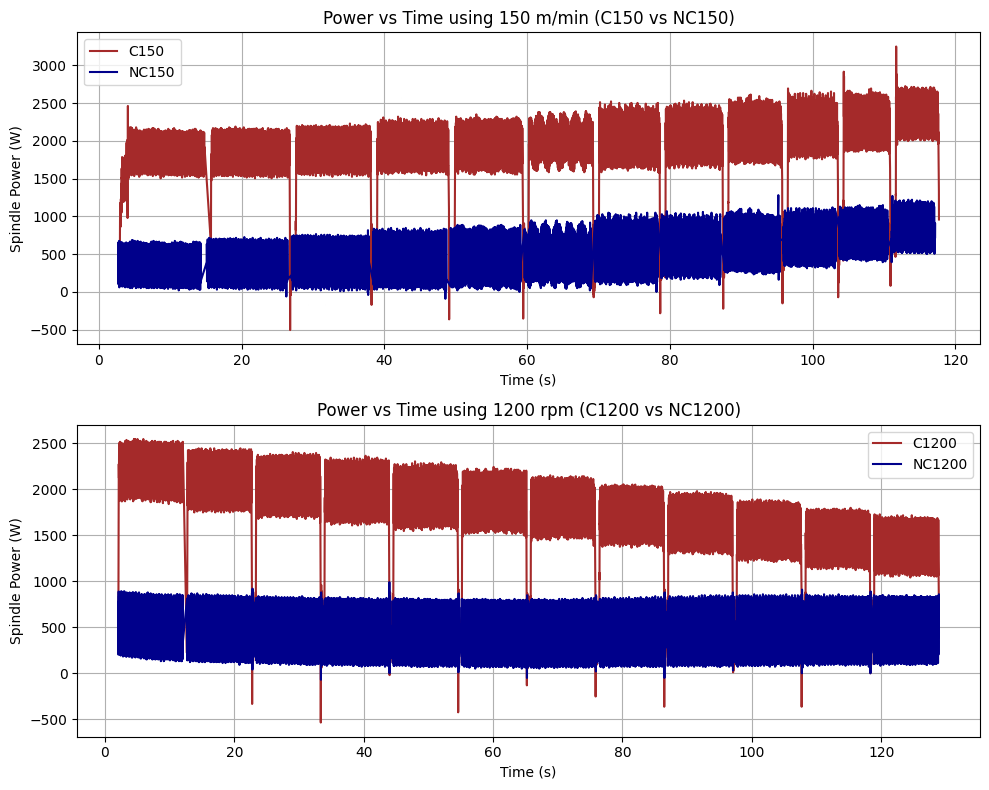

In [11]:
# Overall figure
fig = plt.figure(figsize=(10,8))
gs = gridspec.GridSpec(2, 1)

# Power vs Time using constant cutting velocity
ax1 = fig.add_subplot(gs[0,0])
ax1.plot(filt_dfC150['time'], filt_dfC150['power'], label='C150', color='brown') 
ax1.plot(filt_dfNC150['time'], filt_dfNC150['power'], label='NC150', color='darkblue')
#ax1.set_xlim(25,28)
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Spindle Power (W)')
ax1.set_title('Power vs Time using 150 m/min (C150 vs NC150)')

# Power vs Time using constant spindle speed
ax2 = fig.add_subplot(gs[1,0])
ax2.plot(filt_dfC1200['time'], filt_dfC1200['power'], label='C1200', color='brown') 
ax2.plot(filt_dfNC1200['time'], filt_dfNC1200['power'], label='NC1200', color='darkblue')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Spindle Power (W)')
ax2.set_title('Power vs Time using 1200 rpm (C1200 vs NC1200)')

for ax in [ax1, ax2]:
    ax.grid(True)
    ax.legend()

plt.tight_layout()
# Save figure automatically (duplicate block - saved with v2 suffix)
plt.savefig('images/power_vs_time_150_1200_v2.png', dpi=300, bbox_inches='tight')
plt.show()

In [12]:
# Suppressing glitches
dfs = {'C150': filt_dfC150, 'NC150': filt_dfNC150, 'C1200': filt_dfC1200, 'NC1200': filt_dfNC1200}
cleaned_dfs = {}

for key, df in dfs.items():
    mean_power = df.groupby('prog_pos_x')['power'].mean()
    std_power = df.groupby('prog_pos_x')['power'].std()

    df = df.copy()
    df['mean_power'] = df['prog_pos_x'].map(mean_power)
    df['std_power'] = df['prog_pos_x'].map(std_power)

    mask = (df['power'] > df['mean_power'] - 2 * df['std_power']) & \
           (df['power'] < df['mean_power'] + 2 * df['std_power'])
    df_clean = df[mask].drop(columns=['mean_power', 'std_power'])

    cleaned_dfs[key] = df_clean

filt_dfC150_new = cleaned_dfs['C150']
filt_dfNC150_new = cleaned_dfs['NC150']
filt_dfC1200_new = cleaned_dfs['C1200']
filt_dfNC1200_new = cleaned_dfs['NC1200']

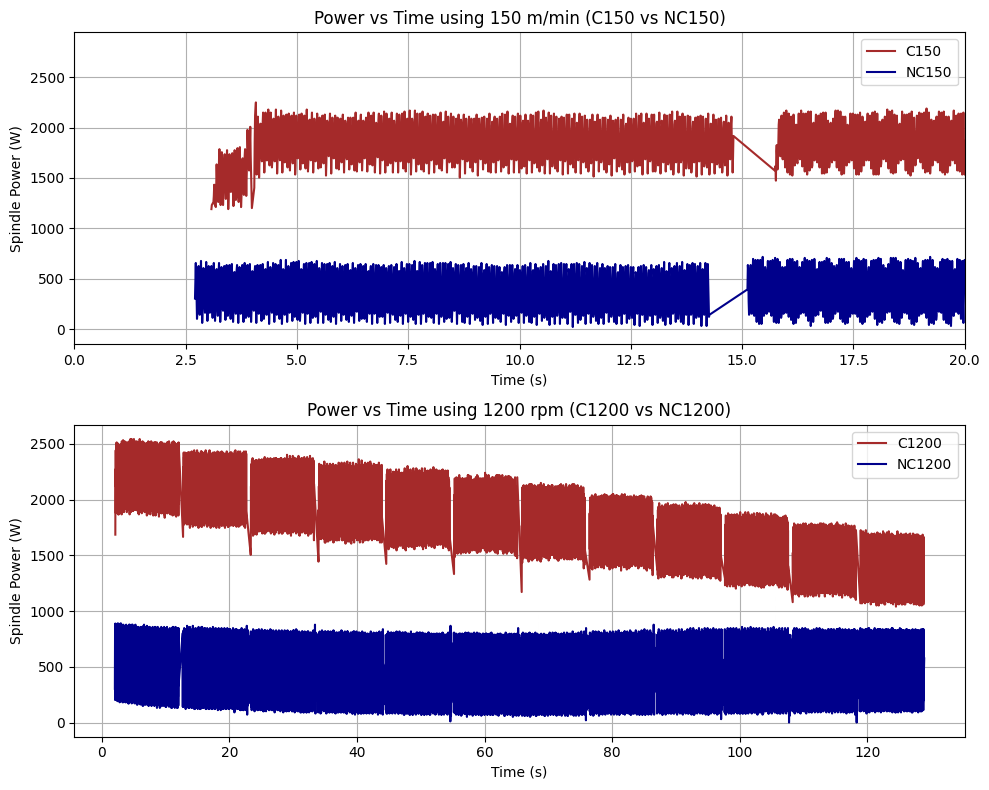

In [13]:
# Overall figure
fig = plt.figure(figsize=(10,8))
gs = gridspec.GridSpec(2, 1)

# Power vs Time using constant cutting velocity
ax1 = fig.add_subplot(gs[0,0])
ax1.plot(filt_dfC150_new['time'], filt_dfC150_new['power'], label='C150', color='brown') 
ax1.plot(filt_dfNC150_new['time'], filt_dfNC150_new['power'], label='NC150', color='darkblue')
ax1.set_xlim(0,20)
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Spindle Power (W)')
ax1.set_title('Power vs Time using 150 m/min (C150 vs NC150)')

# Power vs Time using constant spindle speed
ax2 = fig.add_subplot(gs[1,0])
ax2.plot(filt_dfC1200_new['time'], filt_dfC1200_new['power'], label='C1200', color='brown') 
ax2.plot(filt_dfNC1200_new['time'], filt_dfNC1200_new['power'], label='NC1200', color='darkblue')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Spindle Power (W)')
ax2.set_title('Power vs Time using 1200 rpm (C1200 vs NC1200)')

for ax in [ax1, ax2]:
    ax.grid(True)
    ax.legend()

plt.tight_layout()
# Save figure (power vs time) - duplicate block
plt.savefig('images/power_vs_time_150_1200_v2.png', dpi=300, bbox_inches='tight')
plt.show()

In [14]:
# Vc = 150 -> exclude el.s until t = 4 -> because transitory of PC_C and non useful to evaluate KC
filt_dfC150_new = filt_dfC150_new[filt_dfC150_new['time'] > 4]

## Cutting power

$P_c[i] = P[i]|_{_{C-}} - P[i]|_{_{NC-}}$

dati filtrati:

* riassegna i filtrati


In [15]:
# Re-definition of filtered data frames
filt_dfC150 = filt_dfC150_new
filt_dfNC150 = filt_dfNC150_new
filt_dfC1200 = filt_dfC1200_new
filt_dfNC1200 = filt_dfNC1200_new

In [16]:
# Cutting power calculation
df_150 = pd.DataFrame({
    'time' : filt_dfC150['time'],
    'prog_pos_x' : filt_dfC150['prog_pos_x'],
    'Pc': filt_dfC150['power'] - filt_dfNC150['power']
}).dropna()
df_1200 = pd.DataFrame({
    'time' : filt_dfC1200['time'],
    'prog_pos_x' : filt_dfC1200['prog_pos_x'],
    'Pc': filt_dfC1200['power'] - filt_dfNC1200['power']
}).dropna()

### Constant Cutting Speed

In [17]:
# Cutting Force
df_150['Fc'] = df_150['Pc'] / Vc * 60   #(N)

# Specific Cutting Force
df_150['Kc'] = df_150['Fc'] / (ap * f)   #(N/mm² = MPa)

In [18]:
stats_150 = (
    df_150.groupby('prog_pos_x')[['Pc', 'Fc', 'Kc']]
    .agg(['min', 'max', 'mean', 'std'])
    .reset_index()
    .sort_values(by='prog_pos_x', ascending=False)
)

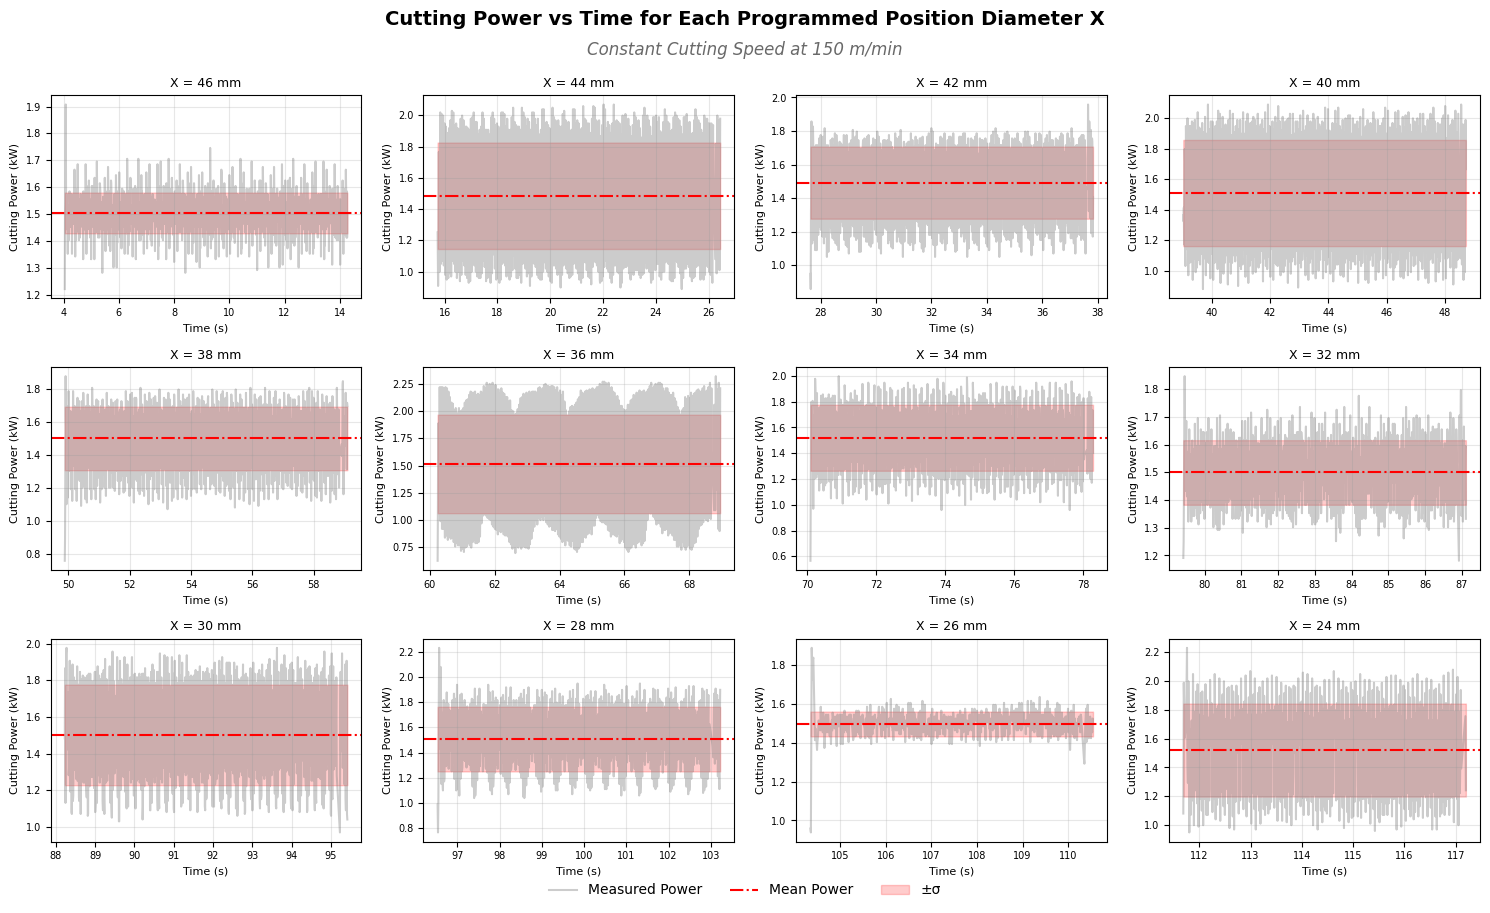

In [19]:
diameters = sorted(df_150['prog_pos_x'].unique(), reverse=True)

n_diam = len(diameters)
n_cols = 4
n_rows = int(np.ceil(n_diam / n_cols))

fig = plt.figure(figsize=(15, n_rows * 3))   # 15 inches wide, auto height scaling
gs = gridspec.GridSpec(n_rows, n_cols)

# Loop through each diameter
for i, x in enumerate(diameters):
    ax = fig.add_subplot(gs[i // n_cols, i % n_cols])

    # Filter data for this diameter
    subset = df_150[df_150['prog_pos_x'] == x].copy()
    subset['Pc'] = subset['Pc'] / 1000

    mean_x = stats_150.loc[stats_150['prog_pos_x'] == x, ('Pc','mean')].values[0] / 1000
    std_x = stats_150.loc[stats_150['prog_pos_x'] == x, ('Pc','std')].values[0] / 1000

    # Plot
    ax.plot(subset['time'], subset['Pc'], color='gray', alpha=0.4, label='Measured Power')
    ax.axhline(mean_x, color='red', linestyle='-.', label='Mean Power')
    ax.fill_between(subset['time'],
                    mean_x - std_x, mean_x + std_x,
                    color='red', alpha=0.2, label='±σ')

    # Labels and formatting
    ax.set_title(f"X = {x:.0f} mm", fontsize=9)
    ax.set_xlabel("Time (s)", fontsize=8)
    ax.set_ylabel("Cutting Power (kW)", fontsize=8)
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=7)

# Remove any empty subplots if grid > number of diameters
for j in range(i + 1, n_rows * n_cols):
    fig.delaxes(fig.axes[j])

# Global figure title and legend
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels,
           loc='lower center',
           bbox_to_anchor=(0.5, -0.02),  # outside bottom margin
           ncol=3,
           frameon=False)
fig.suptitle("Cutting Power vs Time for Each Programmed Position Diameter X", fontsize=14, fontweight='bold')
fig.text(0.5, 0.93, "Constant Cutting Speed at 150 m/min",
         ha='center', fontsize=12, style='italic', color='dimgray')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [20]:
# Round to 3 decimals and add nice table formatting
stats_150_styled = (
    stats_150.style
    .format(precision=3)
    .set_caption("Statistical Summary of Cutting Power, Force, and Specific Cutting Force by Diameter (prog_pos_x)")
    .set_table_styles([
        {'selector': 'caption', 'props': [('font-size', '14px'), ('font-weight', 'bold'), ('text-align', 'center'), ('color', '#2F4F4F')]},
        {'selector': 'th', 'props': [('background-color', '#E3E3E3'), ('color', '#000'), ('text-align', 'center')]},
        {'selector': 'td', 'props': [('text-align', 'center')]}
    ])
    .background_gradient(subset=pd.IndexSlice[:, (slice(None), 'mean')], cmap='Blues') # highlight means
)

stats_150_styled


### Constant Spindle Speed 

In [21]:
# Cutting speed
df_1200['Vc'] = N * np.pi * df_1200['prog_pos_x'] / 1000    #(m/min) 

# Cutting Force
df_1200['Fc'] = df_1200['Pc'] / df_1200['Vc'] * 60   #(N)

# Specific Cutting Force
df_1200['Kc'] = df_1200['Fc'] / (ap * f)   #(N/mm² = MPa)

<function matplotlib.pyplot.show(close=None, block=None)>

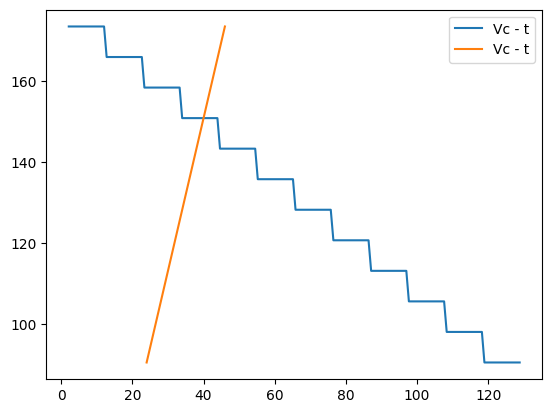

In [22]:
plt.plot(df_1200['time'], df_1200['Vc'], label = 'Vc - t')
plt.plot(df_1200['prog_pos_x'], df_1200['Vc'], label = 'Vc - t')

plt.legend()
plt.show

In [23]:
stats_1200 = (
    df_1200.groupby('prog_pos_x')[['Pc', 'Vc', 'Fc', 'Kc']]
    .agg(['min', 'max', 'mean', 'std'])
    .reset_index()
    .sort_values(by='prog_pos_x', ascending=False)
)

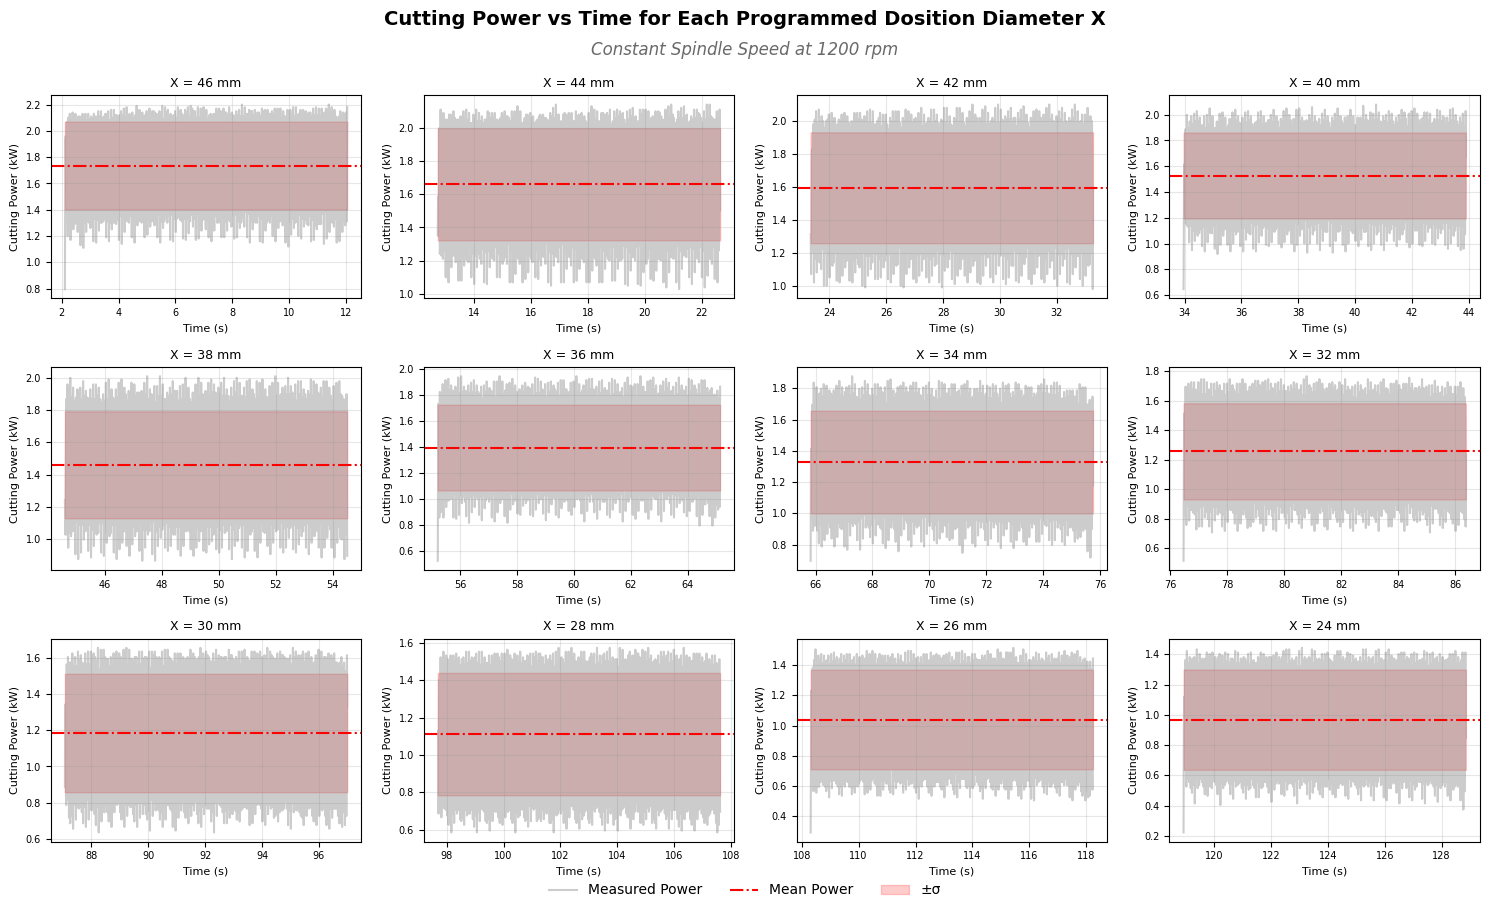

In [24]:
#diameters = sorted(df_150['prog_pos_x'].unique(), reverse=True)
#
#n_diam = len(diameters)
#n_cols = 4
#n_rows = int(np.ceil(n_diam / n_cols))
#
fig = plt.figure(figsize=(15, n_rows * 3))   # 15 inches wide, auto height scaling
gs = gridspec.GridSpec(n_rows, n_cols)

# Loop through each diameter
for i, x in enumerate(diameters):
    ax = fig.add_subplot(gs[i // n_cols, i % n_cols])

    # Filter data for this diameter
    subset = df_1200[df_1200['prog_pos_x'] == x].copy()
    subset['Pc'] = subset['Pc'] / 1000

    mean_x = stats_1200.loc[stats_1200['prog_pos_x'] == x, ('Pc','mean')].values[0] / 1000
    std_x = stats_1200.loc[stats_1200['prog_pos_x'] == x, ('Pc','std')].values[0] / 1000

    # Plot
    ax.plot(subset['time'], subset['Pc'], color='gray', alpha=0.4, label='Measured Power')
    ax.axhline(mean_x, color='red', linestyle='-.', label='Mean Power')
    ax.fill_between(subset['time'],
                    mean_x - std_x, mean_x + std_x,
                    color='red', alpha=0.2, label='±σ')

    # Labels and formatting
    ax.set_title(f"X = {x:.0f} mm", fontsize=9)
    ax.set_xlabel("Time (s)", fontsize=8)
    ax.set_ylabel("Cutting Power (kW)", fontsize=8)
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=7)

# Remove any empty subplots if grid > number of diameters
for j in range(i + 1, n_rows * n_cols):
    fig.delaxes(fig.axes[j])

# Global figure title and legend
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels,
           loc='lower center',
           bbox_to_anchor=(0.5, -0.02),  # outside bottom margin
           ncol=3,
           frameon=False)
fig.suptitle("Cutting Power vs Time for Each Programmed Dosition Diameter X", fontsize=14, fontweight='bold')
fig.text(0.5, 0.93, "Constant Spindle Speed at 1200 rpm",
         ha='center', fontsize=12, style='italic', color='dimgray')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [25]:
# Round to 3 decimals and add nice table formatting
stats_1200_styled = (
    stats_1200.style
    .format(precision=3)
    .set_caption("Statistical Summary of Cutting Power, Force, and Specific Cutting Force by Diameter (prog_pos_x)")
    .set_table_styles([
        {'selector': 'caption', 'props': [('font-size', '14px'), ('font-weight', 'bold'), ('text-align', 'center'), ('color', '#2F4F4F')]},
        {'selector': 'th', 'props': [('background-color', '#E3E3E3'), ('color', '#000'), ('text-align', 'center')]},
        {'selector': 'td', 'props': [('text-align', 'center')]}
    ])
    .background_gradient(subset=pd.IndexSlice[:, (slice(None), 'mean')], cmap='Blues') # highlight means
)

stats_1200_styled